In [108]:
import pandas as pd
import matplotlib.pyplot as plt

import keras
import tensorflow as tf



from sklearn.metrics import confusion_matrix
import seaborn as sns



In [2]:
from keras.applications.vgg16 import VGG16,preprocess_input

In [4]:
import os

print(os.listdir('/kaggle/input'))

['datasets']


In [8]:
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    if files:
        print(files[:5])

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/vivek468
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/pred
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/pred/NORMAL
['NORMAL_1.jpeg', 'NORMAL_2.jpeg', 'NORMAL_3.jpeg', 'NORMAL_4.jpeg']
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/pred/PNEUMONIA
['PNEUMONIA_1.jpeg', 'PNEUMONIA_2.jpeg', 'PNEUMONIA_3.jpeg', 'PNEUMONIA_4.jpeg', 'person2_bacteria_4.jpeg']
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/test
/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/test/NORMAL
['NORMAL-1049278-0001.jpeg', 'NORMAL-1110860-0001.jpeg', 'NORMAL-11419-0001.jpeg', 'NORMAL-115218-0001.jpeg', 'NORMAL-1160949-00

In [63]:
data_dir = '/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/train'

In [64]:


train_ds_original = keras.utils.image_dataset_from_directory(
    directory=data_dir,
    image_size=(224, 224),
    batch_size=32,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='training',
    seed=42,
    shuffle=True
)




Found 7315 files belonging to 2 classes.
Using 5852 files for training.


In [65]:
val_ds_original = keras.utils.image_dataset_from_directory(
    directory=data_dir,
    image_size=(224, 224),
    batch_size=32,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=42,
    shuffle=False
)


Found 7315 files belonging to 2 classes.
Using 1463 files for validation.


In [66]:
print("Classes:", train_ds_original.class_names)

Classes: ['NORMAL', 'PNEUMONIA']


In [68]:
test_ds_original = keras.utils.image_dataset_from_directory(
    directory='/kaggle/input/datasets/vivek468/beginner-chest-xray-image-classification/chest_xray/test',
    image_size=(224, 224),
    batch_size=32,
    labels='inferred',
    label_mode='int',
    shuffle=False
)

Found 620 files belonging to 2 classes.


In [69]:
conv_base=VGG16(
    include_top=False,
    input_shape=(224,224,3),
    weights='imagenet'
)

In [70]:
conv_base.trainable=False

In [71]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [90]:
def process(image, label):
    image = preprocess_input(image)
    return image, label

train_ds = train_ds_original.map(process)
val_ds = val_ds_original.map(process)
test_ds = test_ds_original.map(process)

In [91]:
from keras.layers import Dense,Conv2D,Dropout,BatchNormalization,GlobalAveragePooling2D,Flatten
from keras.models import Sequential
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

from keras import layers

In [92]:

model=Sequential()

model.add(keras.Input(shape=(224,224,3)))

model.add(conv_base)

model.add(GlobalAveragePooling2D())

model.add(Dense(256,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(64,activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(32,activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(1,activation='sigmoid'))




In [93]:
model.compile(optimizer=Adam(learning_rate=0.001),metrics=['accuracy'],loss='binary_crossentropy')

In [94]:
history=model.fit(train_ds,validation_data=val_ds,epochs=10,callbacks=[EarlyStopping(restore_best_weights=True,patience=3,monitor='val_loss')])

Epoch 1/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 51s 249ms/step - accuracy: 0.7114 - loss: 0.6425 - val_accuracy: 0.9412 - val_loss: 0.1473
Epoch 2/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 183ms/step - accuracy: 0.9000 - loss: 0.2631 - val_accuracy: 0.9528 - val_loss: 0.1153
Epoch 3/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 35s 188ms/step - accuracy: 0.9265 - loss: 0.2097 - val_accuracy: 0.9522 - val_loss: 0.1190
Epoch 4/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 185ms/step - accuracy: 0.9404 - loss: 0.1795 - val_accuracy: 0.9515 - val_loss: 0.1125
Epoch 5/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 186ms/step - accuracy: 0.9453 - loss: 0.1627 - val_accuracy: 0.9768 - val_loss: 0.0575
Epoch 6/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 187ms/step - accuracy: 0.9494 - loss: 0.1522 - val_accuracy: 0.9597 - val_loss: 0.0990
Epoch 7/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 186ms/step - accuracy: 0.9518 - loss: 0.1384 - val_accuracy: 0.9686 - val_loss: 0.0781
Epoch 8/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 34s 186ms/step - accuracy: 0.9527 - loss: 0

In [101]:
test_loss,test_accu=model.evaluate(test_ds)

print("Accurarcy on testing data: ",test_accu)
print("Loss on testing data: ",test_loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.9226 - loss: 0.1989
Accurarcy on testing data:  0.9225806593894958
Loss on testing data:  0.1989135593175888


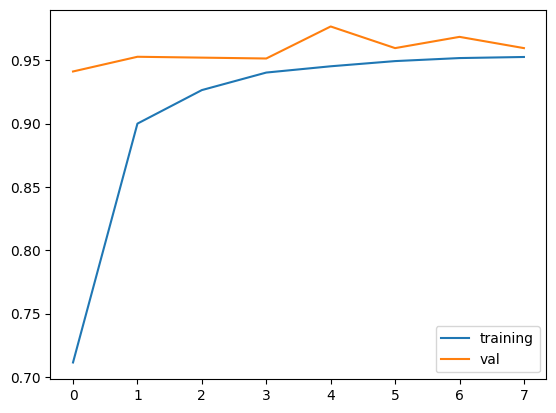

In [102]:
plt.plot(history.history['accuracy'],label='training')
plt.plot(history.history['val_accuracy'],label='val')
plt.legend()
plt.show()

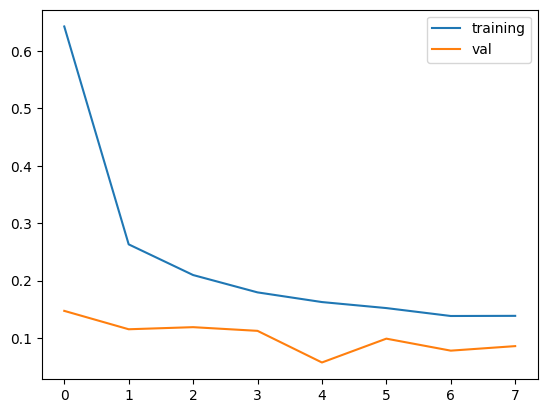

In [103]:
plt.plot(history.history['loss'],label='training')
plt.plot(history.history['val_loss'],label='val')
plt.legend()
plt.show()

In [105]:
print("Training images:", train_ds.cardinality().numpy())
print("Validation images:", val_ds.cardinality().numpy())

Training images: 183
Validation images: 46


20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 163ms/step


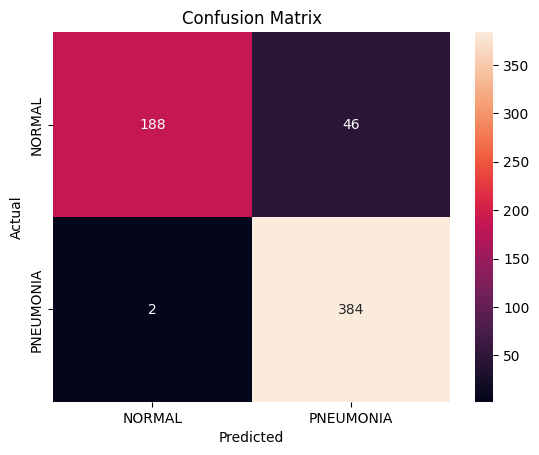

In [109]:

y_true = []
for images, labels in test_ds:
    y_true.extend(labels.numpy())


predictions = model.predict(test_ds)
y_pred = (predictions > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [104]:
model.save('/kaggle/working/chest_xray_classifier.keras')
print("Model saved successfully!")


Model saved successfully!
